# Memory experiment — routing optimization comparison

In [1]:
%pip install qldpc matplotlib sinter scipy "relay-bp[stim]"


Note: you may need to restart the kernel to use updated packages.


In [2]:
import csv
import os
import sys
from collections.abc import Mapping, Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sinter
from matplotlib.figure import Figure
from scipy.stats import beta as beta_distribution

import directional_tile_codes as dtc
from qldpc import circuits, codes, decoders
from qldpc.objects import PauliXZLike
from relay_bp.stim import sinter_decoders as make_relay_sinter_decoders
from tesseract_decoder import make_tesseract_sinter_decoders_dict

In [3]:
def make_decoder_registry() -> dict[str, sinter.Decoder]:
    relay = make_relay_sinter_decoders(
        gamma0=0.1,
        pre_iter=80,
        num_sets=60,
        set_max_iter=60,
        gamma_dist_interval=(-0.24, 0.66),
        stop_nconv=1,
    )
    return {"relay_bp": relay["relay-bp"]}


In [4]:
ERROR_RATES = tuple(np.logspace(-3, -2, 3))
print("Physical error rates (both bases):", ERROR_RATES)
NUM_WORKERS = max(1, min(4, (os.cpu_count() or 1) - 1))

experiment_4 = (300, 60_000, 30_000)
MAX_ERRORS, MAX_SHOTS, _ = experiment_4
CUSTOM_DECODERS = make_decoder_registry()

word_name = "NESEN"
dtc_codes = [
    (dtc.DirectionalTileCode(M=22, N=3, word=dtc.DirectionalWord(word_name)), 4)
]

NOTEBOOKS_DIR = Path(".") if Path.cwd().name == "notebooks" else Path("notebooks")
if not NOTEBOOKS_DIR.is_dir():
    raise FileNotFoundError(
        f"Cannot find the notebooks directory from {Path.cwd()}. "
        "Start Jupyter from the repository root or notebooks/."
    )
RESULTS_DIR = (NOTEBOOKS_DIR / "dtc_comparison_routing_optimization_results" / word_name
               / f"experiment_{MAX_ERRORS}_{MAX_SHOTS // 1000}")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Results directory:", RESULTS_DIR.resolve())
print("Decoder:", list(CUSTOM_DECODERS))
print("Stop per task at", MAX_ERRORS, "errors or", MAX_SHOTS, "shots.")


Physical error rates (both bases): (np.float64(0.001), np.float64(0.0031622776601683794), np.float64(0.01))
Results directory: /Users/frafino/Desktop/directional_codes/notebooks/dtc_comparison_routing_optimization_results/NESEN/experiment_300_60
Decoder: ['relay_bp']
Stop per task at 300 errors or 60000 shots.


## 3. Build only custom directional-memory Sinter tasks

In [5]:
def code_label(code: codes.CSSCode) -> str:
    known_distance = code.get_distance_if_known()
    suffix = f", {known_distance}" if known_distance is not None else ""
    return f"[[{len(code)}, {code.dimension}{suffix}]]"


def build_memory_tasks(
    codes_and_rounds: Sequence[tuple[dtc.DirectionalTileCode, int]],
    basis: PauliXZLike,
    *,
    optimize: bool,
    error_rates: Sequence[float] = ERROR_RATES,
) -> list[sinter.Task]:
    """Build ONLY the custom directional extraction memory circuits."""
    for _, num_rounds in codes_and_rounds:
        if (
            isinstance(num_rounds, (bool, np.bool_))
            or not isinstance(num_rounds, (int, np.integer))
            or num_rounds < 2
            or num_rounds % 2
        ):
            raise ValueError("Each round count must be a positive even integer >= 2.")

    tasks = []
    for tile_code, num_rounds in codes_and_rounds:
        num_rounds = int(num_rounds)
        code = tile_code.css_code
        strategy = dtc.DirectionalSyndromeMeasurement(tile_code, optimize=optimize)
        variant = "optimized" if optimize else "unoptimized"
        layout = strategy.layout
        print(f"{basis}, {variant}: {len(layout.sites)} physical qubits, "
              f"{len(layout.routing_positions)} routing qubits")
        word = "".join(direction.name for direction in tile_code.word.word)

        num_calls = num_rounds // 2
        for probability in error_rates:
            noise = circuits.DepolarizingNoiseModel(
                float(probability),
                include_idling_error=False,
            )
            circuit = circuits.get_memory_experiment(
                code,
                basis=basis,
                num_rounds=num_calls,
                noise_model=noise,
                qubit_ids = strategy.get_qubit_ids(),
                syndrome_measurement_strategy = strategy,
            )
            dem = circuit.detector_error_model()
            num_logicals = int(circuit.num_observables)
            if num_logicals != int(code.dimension):
                raise ValueError(
                    f"{word}, {basis}, directional: circuit tracks "
                    f"{num_logicals} observables, but code has k={code.dimension}. "
                    "Inspect the tracked logical observables before using per-logical-qubit normalization."
                )
            if num_logicals < 1:
                raise ValueError("The circuit tracks no logical observables.")
            tasks.append(
                sinter.Task(
                    circuit=circuit,
                    detector_error_model=dem,
                    json_metadata={
                        "label": code_label(code),
                        "word": word,
                        "basis": str(basis),
                        "strategy": variant,
                        "optimize": optimize,
                        "physical_qubits": len(layout.sites),
                        "routing_qubits": len(layout.routing_positions),
                        "M": int(tile_code.M),
                        "N": int(tile_code.N),
                        "probability": float(probability),
                        "num_rounds": num_rounds,
                        "extraction_calls": num_calls,
                        "num_logicals": num_logicals,
                    },
                )
            )
    return tasks


def run_memory_experiments(
    codes_and_rounds: Sequence[tuple[dtc.DirectionalTileCode, int]],
    basis: PauliXZLike,
    *,
    custom_decoders: Mapping[str, sinter.Decoder] = CUSTOM_DECODERS,
    optimize: bool,
    error_rates: Sequence[float] = ERROR_RATES,
    max_shots: int = MAX_SHOTS,
    max_errors: int = MAX_ERRORS,
    save_resume_filepath: str | None = None,
) -> list[sinter.TaskStats]:
    tasks = build_memory_tasks(codes_and_rounds, basis, optimize=optimize, error_rates=error_rates)
    if not tasks:
        return []
    options = dict(
        tasks=tasks,
        decoders=list(custom_decoders),
        custom_decoders=dict(custom_decoders),
        num_workers=NUM_WORKERS,
        max_shots=max_shots,
        max_errors=max_errors,
        print_progress=True,
    )
    if save_resume_filepath is not None:
        options["save_resume_filepath"] = save_resume_filepath
    return sinter.collect(**options)

## 4. Effective error rates, confidence intervals, and comparison plots

In [6]:
def effective_rate(p_shot: float, per_k_per_round: int) -> float:
    if per_k_per_round <= 0 or not 0 <= p_shot <= 1:
        raise ValueError("Expected positive k*R and shot failure probability in [0, 1].")
    return float(-np.expm1(np.log1p(-p_shot) / per_k_per_round))


def rate_summary(stat: sinter.TaskStats, credible_mass: float = 0.95) -> dict:
    n = int(stat.shots - stat.discards)
    e = int(stat.errors)
    if n <= 0:
        raise ValueError("Cannot estimate a rate without non-discarded shots.")
    if not 0 <= e <= n:
        raise ValueError(f"Invalid failure count {e} for {n} accepted shots.")
    k = int(stat.json_metadata["num_logicals"])
    rounds = int(stat.json_metadata["num_rounds"])
    per_k_per_round = k * rounds
    alpha = (1 - credible_mass) / 2
    lower = beta_distribution.ppf(alpha, e + 0.5, n - e + 0.5)
    upper = beta_distribution.ppf(1 - alpha, e + 0.5, n - e + 0.5)
    return {
        "probability": float(stat.json_metadata["probability"]),
        "decoder": stat.decoder,
        "basis": str(stat.json_metadata["basis"]),
        "strategy": stat.json_metadata["strategy"],
        "physical_qubits": int(stat.json_metadata["physical_qubits"]),
        "routing_qubits": int(stat.json_metadata["routing_qubits"]),
        "word": stat.json_metadata["word"],
        "rounds": rounds,
        "num_logicals": k,
        "shots": int(stat.shots),
        "discards": int(stat.discards),
        "errors": e,
        "p_shot": e / n,
        "p_effective": effective_rate(e / n, per_k_per_round),
        "lower_95": effective_rate(lower, per_k_per_round),
        "upper_95": effective_rate(upper, per_k_per_round),
    }


def plot_optimization_comparison(
    stats: Sequence[sinter.TaskStats],
    *,
    title: str,
) -> tuple[Figure, np.ndarray]:
    figure, axes = plt.subplots(1, 2, figsize=(13, 5.3), sharex=True, sharey=True)
    variants = ("unoptimized", "optimized")
    markers = {"unoptimized": "o", "optimized": "s"}
    colors = dict(zip(variants, plt.get_cmap("tab10").colors))
    labels = {"unoptimized": "Relay-BP — without optimization",
              "optimized": "Relay-BP — with optimization"}
    summaries = [rate_summary(s) for s in stats]
    for i, basis in enumerate(("X", "Z")):
        ax = axes[i]
        group = [r for r in summaries if r["basis"].upper().endswith(basis)]
        for variant in variants:
            points = sorted((r for r in group if r["strategy"] == variant), key=lambda r: r["probability"])
            observed = [r for r in points if r["errors"] > 0]
            if observed:
                xs = np.array([r["probability"] for r in observed])
                ys = np.array([r["p_effective"] for r in observed])
                err_low = np.array([r["p_effective"] - r["lower_95"] for r in observed])
                err_high = np.array([r["upper_95"] - r["p_effective"] for r in observed])
                ax.errorbar(
                    xs, ys, yerr=np.array([err_low, err_high]),
                    color=colors[variant], marker=markers[variant],
                    linestyle="-", capsize=2, linewidth=1.4, markersize=5,
                    label=labels[variant],
                )
            bounds = [r for r in points if r["errors"] == 0]
            offsets = {"unoptimized": 0.99, "optimized": 1.01}

            if bounds:
                ax.scatter(
                    [r["probability"] * offsets[variant] for r in bounds],
                    [r["upper_95"] for r in bounds],
                    color=colors[variant],
                    marker="v",
                    s=65,
                    edgecolors="black",
                    linewidths=0.4,
                    label=f"{labels[variant]} (0 failures; upper bound)",
                    zorder=5,
                )
        ax.set(xscale="log", yscale="log", title=f"{basis}-basis")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend(loc="best", fontsize=8)
        ax.set_xlabel("physical depolarizing probability p")
    axes[0].set_ylabel("effective logical error per round per logical qubit")
    figure.suptitle(title, fontsize=14)
    figure.tight_layout()
    return figure, axes


def write_sinter_csv(path: str, stats: Sequence[sinter.TaskStats]) -> None:
    with open(path, "w", encoding="utf-8") as f:
        print(sinter.CSV_HEADER, file=f)
        for s in stats:
            print(s.to_csv_line(), file=f)


def write_normalized_csv(path: str, stats: Sequence[sinter.TaskStats]) -> None:
    rows = [rate_summary(s) for s in stats]
    if not rows:
        return
    with open(path, "w", encoding="utf-8", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

In [7]:
def checkpoint_path(basis: str, group: str) -> Path:
    return RESULTS_DIR / f"{basis}_{group}_relay_bp_resume.csv"

print("Expected benchmarks per basis:", len(dtc_codes) * len(ERROR_RATES) * 2)
print("X/Z rates:", ERROR_RATES)


Expected benchmarks per basis: 6
X/Z rates: (np.float64(0.001), np.float64(0.0031622776601683794), np.float64(0.01))


## A. Relay-BP — without optimization


In [8]:
unoptimized_stats = []
for basis in ("X", "Z"):
    unoptimized_stats.extend(
        run_memory_experiments(
            dtc_codes,
            basis,
            optimize=False,
            custom_decoders=CUSTOM_DECODERS,
            error_rates=ERROR_RATES,
            max_shots=MAX_SHOTS,
            max_errors=MAX_ERRORS,
            save_resume_filepath=str(checkpoint_path(basis, "unoptimized")),
        )
    )
print("Unoptimized task-decoder results:", len(unoptimized_stats))


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


X, unoptimized: 404 physical qubits, 76 routing qubits


Starting 4 workers...
3 tasks left:
  workers  decoder eta shots_left errors_left json_metadata                                                                                                                                                                                          
        1 relay_bp 51m      59999         300 label=[[165, 2]],word=NESEN,basis=X,strategy=unoptimized,optimize=False,physical_qubits=404,routing_qubits=76,M=22,N=3,probability=0.001,num_rounds=4,extraction_calls=2,num_logicals=2                
        1 relay_bp   ?      60000         300 label=[[165, 2]],word=NESEN,basis=X,strategy=unoptimized,optimize=False,physical_qubits=404,routing_qubits=76,M=22,N=3,probability=0.0031622776601683794,num_rounds=4,extraction_calls=2,num_logicals=2
        2 relay_bp   ?      60000         300 label=[[165, 2]],word=NESEN,basis=X,strategy=unoptimized,optimize=False,physical_qubits=404,routing_qubits=76,M=22,N=3,probability=0.01,num_rounds=4,extraction_calls=2,num_logicals

Z, unoptimized: 404 physical qubits, 76 routing qubits


Starting 4 workers...
3 tasks left:
  workers  decoder eta shots_left errors_left json_metadata                                                                                                                                                                                          
        1 relay_bp 18m      59999         300 label=[[165, 2]],word=NESEN,basis=Z,strategy=unoptimized,optimize=False,physical_qubits=404,routing_qubits=76,M=22,N=3,probability=0.001,num_rounds=4,extraction_calls=2,num_logicals=2                
        1 relay_bp   ?      60000         300 label=[[165, 2]],word=NESEN,basis=Z,strategy=unoptimized,optimize=False,physical_qubits=404,routing_qubits=76,M=22,N=3,probability=0.0031622776601683794,num_rounds=4,extraction_calls=2,num_logicals=2
        2 relay_bp   ?      60000         300 label=[[165, 2]],word=NESEN,basis=Z,strategy=unoptimized,optimize=False,physical_qubits=404,routing_qubits=76,M=22,N=3,probability=0.01,num_rounds=4,extraction_calls=2,num_logicals

Unoptimized task-decoder results: 6


## B. Relay-BP — with optimization


In [9]:
optimized_stats = []
for basis in ("X", "Z"):
    optimized_stats.extend(
        run_memory_experiments(
            dtc_codes,
            basis,
            optimize=True,
            custom_decoders=CUSTOM_DECODERS,
            error_rates=ERROR_RATES,
            max_shots=MAX_SHOTS,
            max_errors=MAX_ERRORS,
            save_resume_filepath=str(checkpoint_path(basis, "optimized")),
        )
    )
print("Optimized task-decoder results:", len(optimized_stats))


X, optimized: 392 physical qubits, 64 routing qubits


Starting 4 workers...
3 tasks left:
  workers  decoder eta shots_left errors_left json_metadata                                                                                                                                                                                       
        1 relay_bp 38m      59999         300 label=[[165, 2]],word=NESEN,basis=X,strategy=optimized,optimize=True,physical_qubits=392,routing_qubits=64,M=22,N=3,probability=0.001,num_rounds=4,extraction_calls=2,num_logicals=2                
        1 relay_bp   ?      60000         300 label=[[165, 2]],word=NESEN,basis=X,strategy=optimized,optimize=True,physical_qubits=392,routing_qubits=64,M=22,N=3,probability=0.0031622776601683794,num_rounds=4,extraction_calls=2,num_logicals=2
        2 relay_bp   ?      60000         300 label=[[165, 2]],word=NESEN,basis=X,strategy=optimized,optimize=True,physical_qubits=392,routing_qubits=64,M=22,N=3,probability=0.01,num_rounds=4,extraction_calls=2,num_logicals=2          

Z, optimized: 392 physical qubits, 64 routing qubits


Starting 4 workers...
3 tasks left:
  workers  decoder eta shots_left errors_left json_metadata                                                                                                                                                                                       
        1 relay_bp   ?      60000         300 label=[[165, 2]],word=NESEN,basis=Z,strategy=optimized,optimize=True,physical_qubits=392,routing_qubits=64,M=22,N=3,probability=0.001,num_rounds=4,extraction_calls=2,num_logicals=2                
        1 relay_bp 41m      59999         300 label=[[165, 2]],word=NESEN,basis=Z,strategy=optimized,optimize=True,physical_qubits=392,routing_qubits=64,M=22,N=3,probability=0.0031622776601683794,num_rounds=4,extraction_calls=2,num_logicals=2
        2 relay_bp   ?      60000         300 label=[[165, 2]],word=NESEN,basis=Z,strategy=optimized,optimize=True,physical_qubits=392,routing_qubits=64,M=22,N=3,probability=0.01,num_rounds=4,extraction_calls=2,num_logicals=2          

Optimized task-decoder results: 6


## C. Replot

Read 12 task-decoder results from:
   dtc_comparison_routing_optimization_results/NESEN/experiment_300_60/X_unoptimized_relay_bp_resume.csv
   dtc_comparison_routing_optimization_results/NESEN/experiment_300_60/X_optimized_relay_bp_resume.csv
   dtc_comparison_routing_optimization_results/NESEN/experiment_300_60/Z_unoptimized_relay_bp_resume.csv
   dtc_comparison_routing_optimization_results/NESEN/experiment_300_60/Z_optimized_relay_bp_resume.csv


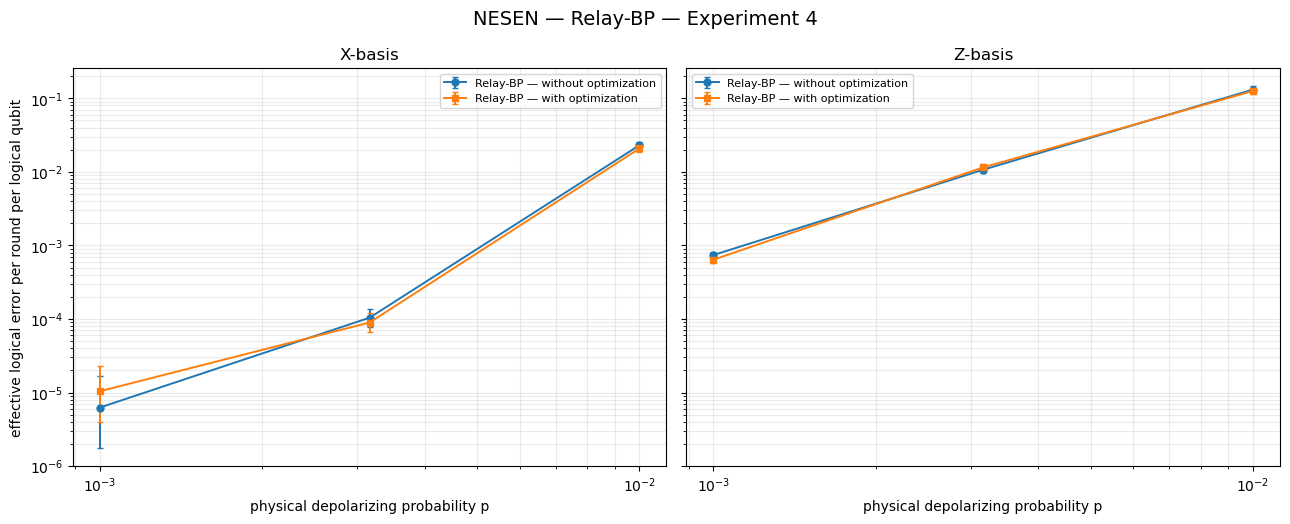

In [10]:
checkpoint_files = [
    checkpoint_path(basis, group)
    for basis in ("X", "Z")
    for group in ("unoptimized", "optimized")
    if checkpoint_path(basis, group).is_file()
    and checkpoint_path(basis, group).stat().st_size > 0
]
if not checkpoint_files:
    raise FileNotFoundError(
        f"No new checkpoints in {RESULTS_DIR}. "
        "Run block A and/or B first, or load your earlier CSV separately."
    )

# Each checkpoint is loaded ONCE. Never include an aggregate/export of these files here.
all_stats = sinter.read_stats_from_csv_files(*checkpoint_files)
if not all_stats:
    raise ValueError("Checkpoint files exist but contain no completed shots yet.")
print("Read", len(all_stats), "task-decoder results from:")
for path in checkpoint_files:
    print("  ", path)

# Checkpoints are dedicated to this comparison; avoid mixing other decoders.
if any(s.decoder != "relay_bp" or s.json_metadata["strategy"] not in
       ("unoptimized", "optimized") for s in all_stats):
    raise ValueError("Unexpected decoder or strategy in these checkpoints.")
fig, axes = plot_optimization_comparison(
    all_stats, title=f"{word_name} — Relay-BP — Experiment 4"
)
fig.savefig(
    RESULTS_DIR / "optimization_comparison.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

write_sinter_csv(str(RESULTS_DIR / "separate_stats.csv"), all_stats)
write_normalized_csv(str(RESULTS_DIR / "separate_effective_rates.csv"), all_stats)